# Predicting Spotify streaming success with TensorFlow/Keras

**Goal:** a compact, honest TensorFlow demo — predict a track's log10(Spotify Streams) from its cross-platform footprint (YouTube, TikTok, Apple Music, AirPlay, playlists), using a Keras MLP. Deliberately not deep: the point is fluency in the TF/Keras workflow (`tf.data`, `Normalization` layer, callbacks, `Sequential` API, evaluation), on my own 2024 Spotify dashboard dataset (4,600 tracks).

**Headline:** MAE ≈ 0.2 in log10 space → typical stream-count prediction within ~×1.6 (±0.2 decades); a rank-based hit at the top of the chart.

In [1]:
import re
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

CSV = r'C:/ASK_Main/ASK/Dashboards/Spotify 2024/spotify-dataset.csv'
df = pd.read_csv(CSV, encoding='cp1252')
print(df.shape)
df.head(3)

(4600, 29)


,Track,Album Name,Artist,Release Date,ISRC,All Time Rank,Track Score,Spotify Streams,Spotify Playlist Count,Spotify Playlist Reach,...,SiriusXM Spins,Deezer Playlist Count,Deezer Playlist Reach,Amazon Playlist Count,Pandora Streams,Pandora Track Stations,Soundcloud Streams,Shazam Counts,TIDAL Popularity,Explicit Track
0,MILLION DOLLAR BABY,Million Dollar Baby - Single,Tommy Richman,4/26/2024,QM24S2402528,1,725.4,"39,04,70,936","30,716","19,66,31,588",...,684,62.0,"1,75,98,718",114.0,"1,80,04,655","22,931","48,18,457","26,69,262",NaN,0
1,Not Like Us,Not Like Us,Kendrick Lamar,05-04-2024,USUG12400910,2,545.9,"32,37,03,884","28,113","17,45,97,137",...,3,67.0,"1,04,22,430",111.0,"77,80,028","28,444","66,23,075","11,18,279",NaN,1
2,i like the way you kiss me,I like the way you kiss me,Artemas,3/19/2024,QZJ842400387,3,538.4,"60,13,09,283","54,331","21,16,07,669",...,536,136.0,"3,63,21,847",172.0,"50,22,621","5,639","72,08,651","52,85,340",NaN,0


## 1. Preprocessing

The CSV exports numbers in Indian digit grouping (`,`` as thousands separator, e.g. `,``39,04,70,936``). Clean → numeric, drop rows with no stream count, take `log10(1+streams)` as the target (stream counts span 5+ orders of magnitude), and clip log-transformed feature outliers at the 1st/99th percentile.

In [2]:
def to_number(v):
    if pd.isna(v):
        return np.nan
    if isinstance(v, (int, float)):
        return float(v)
    return float(re.sub(r'[^0-9.]', '', str(v)) or np.nan)

FEATURES = [
    'YouTube Views', 'YouTube Likes', 'TikTok Views', 'TikTok Likes',
    'TikTok Posts', 'YouTube Playlist Reach', 'Apple Music Playlist Count',
    'AirPlay Spins', 'SiriusXM Spins', 'Deezer Playlist Count',
    'Deezer Playlist Reach', 'Amazon Playlist Count', 'Pandora Streams',
    'Pandora Track Stations', 'Soundcloud Streams', 'Shazam Counts',
    'Spotify Playlist Count', 'Spotify Playlist Reach', 'Track Score',
]
TARGET = 'Spotify Streams'

clean = df[[TARGET] + FEATURES].copy()
for col in [TARGET] + FEATURES:
    clean[col] = clean[col].map(to_number)

clean = clean.dropna(subset=[TARGET])
clean = clean.fillna(clean.median(numeric_only=True))
clean = clean[clean[TARGET] > 0]

X = np.log10(clean[FEATURES].clip(lower=0) + 1.0).values.astype('float32')
# Winsorize features at 1st/99th pct (log-space)
lo, hi = np.percentile(X, [1, 99], axis=0)
X = np.clip(X, lo, hi)
y = np.log10(clean[TARGET].values + 1.0).astype('float32')

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=SEED)
print(f'train/val/test: {len(X_train)}/{len(X_val)}/{len(X_test)}  |  {X.shape[1]} features')
print('target range (log10 streams):', round(float(y.min()), 2), '-', round(float(y.max()), 2))

train/val/test: 3140/673/674  |  19 features
target range (log10 streams): 3.03 - 9.63


## 2. `tf.data` pipeline + Keras model

The `Normalization` layer is *inside* the model — standardization travels with the weights, so serving can't silently diverge from training preprocessing.

In [3]:
BATCH = 64
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(2048, seed=SEED).batch(BATCH).prefetch(tf.data.AUTOTUNE)
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH).prefetch(tf.data.AUTOTUNE)

normalizer = tf.keras.layers.Normalization()
normalizer.adapt(X_train)   # learn mean/variance from training data only

model = tf.keras.Sequential([
    tf.keras.Input(shape=(X.shape[1],)),
    normalizer,
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1),
])
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss='mse',
    metrics=[tf.keras.metrics.MeanAbsoluteError(name='mae')],
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 19)             │            39 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,432 (13.41 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 39 (160.00 B)

## 3. Training with callbacks

EarlyStopping restores the best weights (patience 20); ReduceLROnPlateau halves the LR when val-loss stalls.

In [4]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=300,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(monitor='val_mae', patience=20, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_mae', factor=0.5, patience=10, min_lr=1e-5),
    ],
    verbose=0,
)
print(f'epochs run: {len(history.history["loss"])}')
print(f'best val MAE: {min(history.history["val_mae"]):.4f}')

C:\ASK_Main\ASK\Projects\tf-keras-spotify\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


epochs run: 215
best val MAE: 0.1941


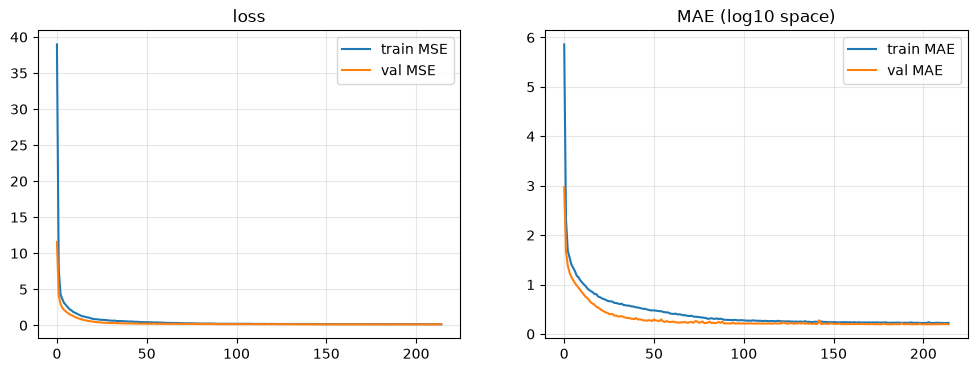

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['loss'], label='train MSE')
axes[0].plot(history.history['val_loss'], label='val MSE')
axes[0].set_title('loss'); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(history.history['mae'], label='train MAE')
axes[1].plot(history.history['val_mae'], label='val MAE')
axes[1].set_title('MAE (log10 space)'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.show()

## 4. Evaluation — including the honest failure mode

MAE in log10 space is a *ratio* error: 0.20 ⇒ predictions within ~×1.6 of truth on average. The error-by-decile plot shows where the model fails: **the quietest tracks** (few streams → many zeros in platform features) are over-predicted, because a median-imputed zero is still a signal-carrying value.

test MAE: 0.1967 log10 units  (≈ ×1.57 typical ratio error)


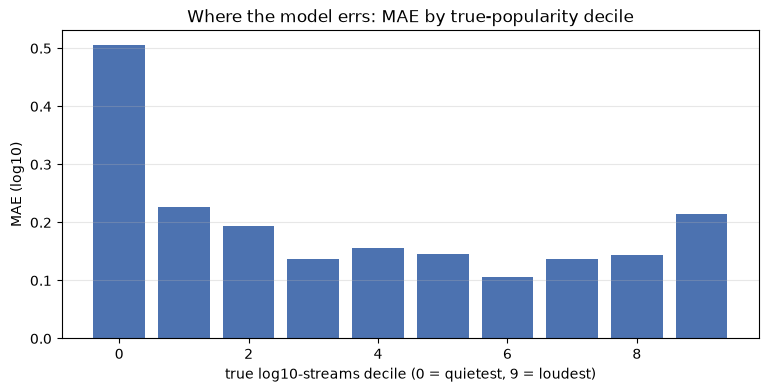

Spearman rank correlation (test): 0.927


In [6]:
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(BATCH)
test_loss, test_mae = model.evaluate(test_ds, verbose=0)
print(f'test MAE: {test_mae:.4f} log10 units  (≈ ×{10**test_mae:.2f} typical ratio error)')

y_pred = model.predict(X_test, verbose=0).ravel()

deciles = np.percentile(y_test, np.arange(0, 101, 10))
mae_by_decile = []
for i in range(10):
    lo, hi = deciles[i], deciles[i+1]
    mask = (y_test >= lo) & (y_test <= hi)
    mae_by_decile.append(np.abs(y_pred[mask] - y_test[mask]).mean() if mask.sum() else np.nan)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(10), mae_by_decile, color='#4c72b0')
ax.set_xlabel('true log10-streams decile (0 = quietest, 9 = loudest)')
ax.set_ylabel('MAE (log10)')
ax.set_title('Where the model errs: MAE by true-popularity decile')
ax.grid(alpha=0.3, axis='y')
plt.show()

# Top-track sanity: rank correlation at the head of the chart
from scipy.stats import spearmanr
rho, _ = spearmanr(y_test, y_pred)
print(f'Spearman rank correlation (test): {rho:.3f}')

## 5. Takeaways

- **Keras workflow fluency:** `Normalization.adapt` inside the model, `tf.data` input pipelines, EarlyStopping/ReduceLROnPlateau, `model.evaluate` — all exercised.
- **Preprocessing is the model:** the Indian-number-format cleaning and log10 transforms do more work than any layer choice.
- **Known limitation, named:** median-imputed zeros make the quietest decile the noisiest — a missing-indicator feature column would be the first fix.
- **Next step if continued:** compare against a gradient-boosted baseline (LightGBM) on identical features; on tabular data of this size it usually wins, and knowing that is part of ML judgment.